# Bivariate Analysis


## 1. Understanding Bivariate Analysis

Bivariate analysis is the process of studying two variables together to understand their relationship.

There are three common combinations:

1. Numerical vs Numerical: Example — age and salary.
2. Categorical vs Numerical: Example — department and salary.
3. Categorical vs Categorical: Example — department and employee status.

**AI/ML relevance:** Bivariate analysis helps us understand feature relationships and investigate which features may be useful for predicting a target variable.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")



## 2. Load the Dataset

We use the same dataset from the previous notebooks to maintain consistency throughout Sprint 4.


In [2]:

df = pd.read_csv("ml_training_data.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Shape: (5, 3)


,Study_Hours,Attendance,Exam_Marks
0,2,60,50
1,3,65,55
2,4,75,65
3,5,85,75
4,6,95,90



## 3. Identify Numerical and Categorical Features

Numerical features contain measurable numbers. Categorical features represent groups or labels.

We identify these columns to choose the correct method for analyzing relationships between two variables.


In [3]:

numerical_cols = df.select_dtypes(include=np.number).columns.tolist()

categorical_cols = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical columns:", numerical_cols)
print("Categorical columns:", categorical_cols)


Numerical columns: ['Study_Hours', 'Attendance', 'Exam_Marks']
Categorical columns: []



## 4. Numerical vs Numerical Analysis

This analysis examines the relationship between two numerical variables.

A scatter plot helps us identify positive relationships, negative relationships, clusters, and unusual observations.

Example: Studying whether an increase in study hours is associated with an increase in exam marks.


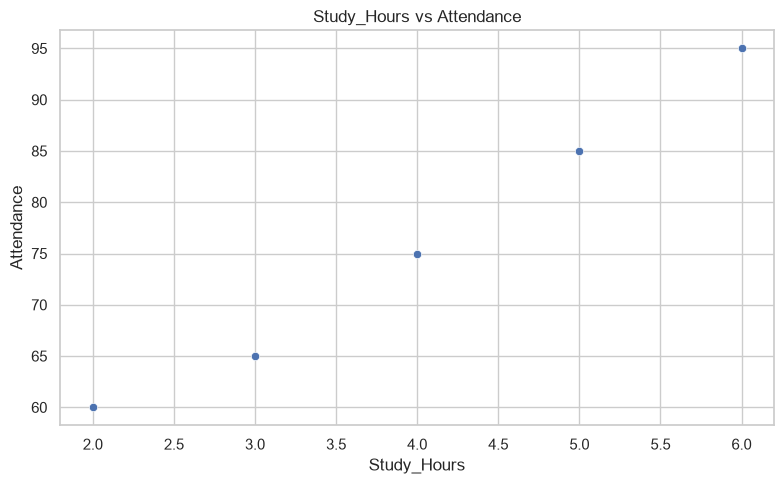

Selected variables: Study_Hours and Attendance


In [4]:

if len(numerical_cols) >= 2:
    x_col = numerical_cols[0]
    y_col = numerical_cols[1]

    pair_df = df[[x_col, y_col]].dropna()

    plt.figure(figsize=(8, 5))
    sns.scatterplot(data=pair_df, x=x_col, y=y_col)
    plt.title(f"{x_col} vs {y_col}")
    plt.tight_layout()
    plt.show()

    print("Selected variables:", x_col, "and", y_col)
else:
    print("At least two numerical columns are needed.")



### Interpretation

- An upward pattern may indicate a positive relationship.
- A downward pattern may indicate a negative relationship.
- A random pattern may indicate a weak or unclear relationship.
- Separate clusters may indicate different groups in the data.

A visible pattern does not prove that one variable causes the other.



## 5. Correlation Analysis

Correlation measures the strength and direction of a linear relationship between two numerical variables.

The Pearson correlation coefficient ranges from -1 to +1.

- Close to +1: strong positive linear relationship.
- Close to -1: strong negative linear relationship.
- Close to 0: weak or no linear relationship.

Correlation does not imply causation and may not capture nonlinear relationships.


In [5]:

if len(numerical_cols) >= 2:
    correlation = df[numerical_cols].corr(numeric_only=True)
    display(correlation.round(2))

    x_col = numerical_cols[0]
    y_col = numerical_cols[1]

    corr_value = df[x_col].corr(df[y_col])
    print(f"Correlation between {x_col} and {y_col}: {corr_value:.3f}")
else:
    print("At least two numerical columns are needed.")


,Study_Hours,Attendance,Exam_Marks
Study_Hours,1.00,0.99,0.99
Attendance,0.99,1.00,1.00
Exam_Marks,0.99,1.00,1.00


Correlation between Study_Hours and Attendance: 0.994



## 6. Correlation Heatmap

A correlation heatmap displays correlation coefficients using colors.

It helps us compare relationships across multiple pairs of numerical features.


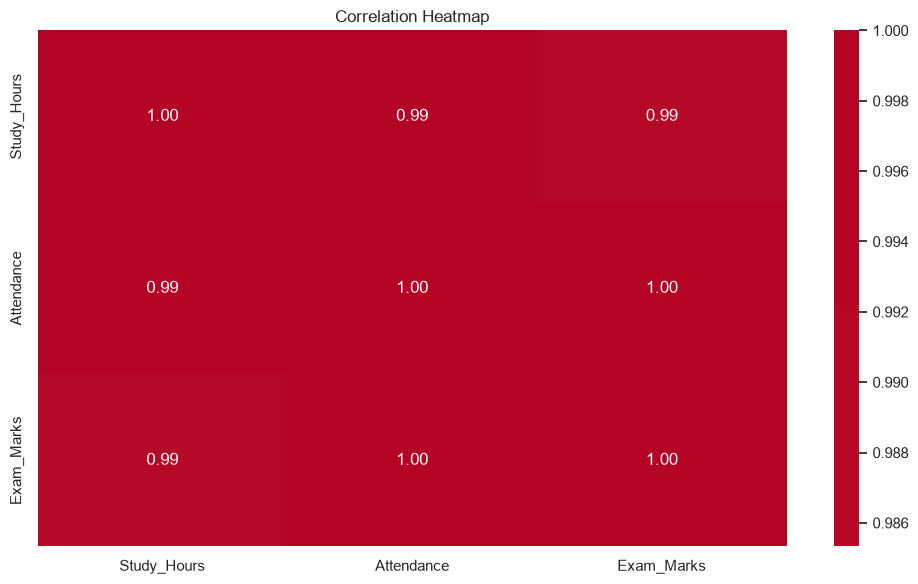

In [6]:

if len(numerical_cols) >= 2:
    plt.figure(figsize=(10, 6))
    sns.heatmap(
        df[numerical_cols].corr(numeric_only=True),
        annot=True,
        cmap="coolwarm",
        fmt=".2f",
        center=0
    )
    plt.title("Correlation Heatmap")
    plt.tight_layout()
    plt.show()
else:
    print("At least two numerical columns are needed.")



## 7. Categorical vs Numerical Analysis

This analysis compares a numerical feature across different categories.

Grouped statistics help us compare the mean, median, and spread of a numerical feature for each category.


In [7]:

if categorical_cols and numerical_cols:
    cat_col = categorical_cols[0]
    num_col = numerical_cols[0]

    grouped_summary = df.groupby(cat_col, dropna=False)[num_col].agg(
        ["count", "mean", "median", "std", "min", "max"]
    )

    display(grouped_summary.round(2))
else:
    print("At least one categorical and one numerical column are needed.")


At least one categorical and one numerical column are needed.



## 8. Box Plot: Numerical Feature by Category

A grouped box plot compares the distribution of a numerical feature across categories.

It helps us compare medians, variability, and potential outliers between groups.


In [8]:

if categorical_cols and numerical_cols:
    cat_col = categorical_cols[0]
    num_col = numerical_cols[0]

    plot_df = df[[cat_col, num_col]].dropna(subset=[num_col])
    top_categories = plot_df[cat_col].value_counts().head(10).index
    plot_df = plot_df[plot_df[cat_col].isin(top_categories)]

    plt.figure(figsize=(10, 5))
    sns.boxplot(data=plot_df, x=cat_col, y=num_col)
    plt.title(f"{num_col} by {cat_col}")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("Suitable categorical and numerical columns are not available.")


Suitable categorical and numerical columns are not available.



## 9. Categorical vs Categorical Analysis

This analysis studies the relationship between two categorical variables.

A cross-tabulation table counts the observations for each combination of categories.


In [11]:

if len(categorical_cols) >= 2:
    cat1 = categorical_cols[0]
    cat2 = categorical_cols[1]

    cross_table = pd.crosstab(
        df[cat1],
        df[cat2],
        dropna=False
    )

    display(cross_table)
else:
    print("At least two categorical columns are needed.")


At least two categorical columns are needed.



## 10. Stacked Bar Chart

A stacked bar chart displays how categories of one variable are distributed within categories of another variable.

It helps compare the composition of groups.


In [12]:

if len(categorical_cols) >= 2:
    cat1 = categorical_cols[0]
    cat2 = categorical_cols[1]

    cross_table = pd.crosstab(df[cat1], df[cat2])
    cross_table = cross_table.loc[
        cross_table.sum(axis=1).sort_values(ascending=False).head(10).index
    ]

    cross_table.plot(kind="bar", stacked=True, figsize=(10, 5))
    plt.title(f"{cat1} vs {cat2}")
    plt.xlabel(cat1)
    plt.ylabel("Count")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("At least two categorical columns are needed.")


At least two categorical columns are needed.



## 11. Relationship with the Target Variable

When a dataset has a target variable, we can study how individual features relate to it.

For a numerical target, correlation may be useful. For a categorical target, grouped statistics and category counts may help.

We should identify the true target column from the dataset documentation rather than assuming that a particular column is the target.


In [14]:

print("Available columns:")
for col in df.columns:
    print("-", col)

target_col = input(
    "Enter the target column name exactly as shown above, "
    "or press Enter to skip: "
).strip()

if target_col and target_col in df.columns:
    if target_col in numerical_cols:
        other_numeric = [c for c in numerical_cols if c != target_col]

        if other_numeric:
            target_corr = (
                df[other_numeric + [target_col]]
                .corr(numeric_only=True)[target_col]
                .drop(target_col)
                .sort_values(key=abs, ascending=False)
            )
            display(target_corr.to_frame("Correlation with target"))
        else:
            print("No other numerical features are available.")

    elif target_col in categorical_cols:
        other_categorical = [c for c in categorical_cols if c != target_col]

        if other_categorical:
            feature = other_categorical[0]
            display(pd.crosstab(df[feature], df[target_col]))
        elif numerical_cols:
            feature = numerical_cols[0]
            display(df.groupby(target_col, dropna=False)[feature].agg(
                ["count", "mean", "median"]
            ).round(2))
        else:
            print("No other features are available for comparison.")
    else:
        print("Target column type needs additional inspection.")
elif target_col:
    print("Column not found. Check the spelling and try again.")
else:
    print("Target analysis skipped.")


Available columns:
- Study_Hours
- Attendance
- Exam_Marks


Enter the target column name exactly as shown above, or press Enter to skip:  Exam_Marks


,Correlation with target
Attendance,0.995624
Study_Hours,0.985329



## 12. Identify Strong Numerical Relationships

We examine correlations between numerical features to identify pairs with relatively strong positive or negative linear relationships.

These pairs may deserve further investigation. Strong correlation does not automatically mean a feature should be removed.


In [15]:

if len(numerical_cols) >= 2:
    corr_matrix = df[numerical_cols].corr(numeric_only=True)

    upper_triangle = corr_matrix.where(
        np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
    )

    strongest_pairs = (
        upper_triangle.stack()
        .rename("Correlation")
        .to_frame()
    )

    strongest_pairs["Absolute Correlation"] = (
        strongest_pairs["Correlation"].abs()
    )

    display(
        strongest_pairs.sort_values(
            "Absolute Correlation", ascending=False
        ).head(10).round(3)
    )
else:
    print("At least two numerical columns are needed.")


Correlation  Absolute Correlation
Attendance  Exam_Marks         0.996                 0.996
Study_Hours Attendance         0.994                 0.994
            Exam_Marks         0.985                 0.985
            Study_Hours          NaN                   NaN
Attendance  Study_Hours          NaN                   NaN
            Attendance           NaN                   NaN
Exam_Marks  Study_Hours          NaN                   NaN
            Attendance           NaN                   NaN
            Exam_Marks           NaN                   NaN

## 13. Observations and Insights

**1. Which two numerical features have the strongest linear relationship?**

The correlation table helps identify the two numerical features with the strongest linear relationship among `Study_Hours`, `Attendance`, and `Exam_Marks`.

**2. Is the relationship positive or negative?**

A positive relationship means both variables tend to increase together. A negative relationship means one variable tends to decrease when the other increases. The correlation coefficient shows the direction of the relationship.

**3. How does the selected numerical feature differ across categories?**

The dataset contains numerical features. Grouped summaries and box plots can be used to compare numerical values across categories if categorical columns are available.

**4. What patterns appear in the categorical cross-tabulation?**

The cross-tabulation helps identify patterns between categorical variables. If the dataset does not contain categorical columns, this analysis is not applicable.

**5. Which features appear related to the target variable, if one is identified?**

If `Exam_Marks` is selected as the target variable, I can examine how `Study_Hours` and `Attendance` are related to exam marks using correlation values and scatter plots.

**6. Are any relationships unexpected or worth investigating further?**

Unusual correlation values, outliers, and unexpected patterns should be investigated further. Missing values and the meaning of each feature should also be considered before drawing conclusions.


## 14. AI/ML Relevance

Bivariate analysis supports machine learning by helping us:

- Understand relationships between features.
- Investigate how features vary across target classes.
- Detect potentially redundant numerical features.
- Compare numerical values across categories.
- Generate hypotheses for feature engineering and further analysis.

The findings should be validated and interpreted in context before making modeling decisions.
